# Week 07 — YCB-V CNN Classification I
**Main Quest:** Convolutional Neural Networks  
**Side Quest:** CNN Classification I — a clean CNN baseline on the same BOP/YCB-V object subset.

This notebook continues the **executed** previous week's experiments. It builds a CNN baseline without changing the original scene-based split, five class IDs, 64×64 inputs, or Week 06 selected aspect-preserving preprocessing.

## A. Locked experimental protocol

| Variable | Week 07 decision | Why |
|---|---|---|
| Source data | Hugging Face `bop-benchmark/ycbv`: `ycbv_base.zip` + `ycbv_test_bop19.zip` | Same as Week 03–06, **not** the full YCB-V release |
| Classes (ordered IDs) | `[4, 3, 1, 6, 12]` | Same five classes and label indices as Week 06 |
| Split | Reproduce 877 train / 375 validation / 450 test across 8 / 2 / 2 scenes | Prevent train/test leakage |
| Crop | 8% bbox padding; aspect-preserving 64×64 letterbox | **X2**, selected in Week 06 |
| Normalization | RGB tensor in [-1, 1] using mean/std 0.5 | Match Week 06 |
| Architecture | Week 06 `CompactCNN`, now on X2 inputs | Clean CNN architecture baseline; no unplanned sweep |
| Training | Adam lr=0.001, weight decay=1e-4, dropout=0.30; batch size 64; max 15 epochs; patience 4 | Match Week 06 training protocol |
| Selection | Minimum **validation loss** only | Test set cannot select checkpoint or hyperparameters |
| Test | Single final evaluation on original 450 held-out samples | Keep the historical benchmark interpretable |

**Comparison:** Week 06 X2 MLP test accuracy=0.6289, macro-F1=0.6468. Week 06 `X3_compact_cnn` mean development macro-F1=0.7166 used **direct square resize**, so it is an informative historical result, *not a matched-preprocessing CNN-vs-MLP comparison*. The Week 07 CNN uses letterbox to make the comparison with Week 06 X2 cleaner, but results can still differ because of run conditions. Do not use historical test scores to iteratively tune Week 07.

## B. Imports, seeds and configuration

In [1]:
import sys, subprocess, importlib.util
for module, package in [('huggingface_hub','huggingface_hub'), ('reportlab','reportlab'), ('sklearn','scikit-learn')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])

In [2]:
from pathlib import Path
from datetime import datetime, timezone
from PIL import Image, ImageOps
import copy, json, os, random, zipfile, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
from IPython.display import display

SEED = 42
CLASSES = ['tomato_soup_can', 'sugar_box', 'master_chef_can', 'tuna_fish_can', 'bleach_cleanser']
SELECTED_OBJ_IDS = [4, 3, 1, 6, 12]
CLASS_TO_INDEX = dict(zip(SELECTED_OBJ_IDS,range(5)))
IMAGE_SIZE, BATCH_SIZE = 64, 64
MAX_EPOCHS, EARLY_STOPPING_PATIENCE = 15, 4
LR, WEIGHT_DECAY, DROPOUT = 1e-3, 1e-4, .30
MIN_VISIBILITY, MIN_BOX_SIDE = .35, 24
MAX_TRAIN_PER_CLASS, MAX_VAL_PER_CLASS, MAX_TEST_PER_CLASS = 600, 150, 150
DATASET_ROOT = Path('datasets/ycbv')
OUTPUT_DIR = Path('outputs/week07')
CHECKPOINT_DIR = OUTPUT_DIR/'checkpoints'
for p in [DATASET_ROOT, OUTPUT_DIR, CHECKPOINT_DIR]: p.mkdir(parents=True,exist_ok=True)

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_everything()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, '| PyTorch:',torch.__version__)
print('Class order:', dict(enumerate(CLASSES)))

Device: cuda | PyTorch: 2.11.0+cu130
Class order: {0: 'tomato_soup_can', 1: 'sugar_box', 2: 'master_chef_can', 3: 'tuna_fish_can', 4: 'bleach_cleanser'}


## C. Load the exact BOP subset and reconstruct the fixed scene split
**Important:** Here `test/` is the directory name used inside the public BOP'19 source release. We construct our own internal train/validation/test split *within* those scenes; our 450-sample test result is **not an official BOP/YCB-V challenge score**.

In [3]:
from huggingface_hub import hf_hub_download
REPO_ID='bop-benchmark/ycbv'

def dataset_ready(root):
    test=root/'test'
    return test.is_dir() and any(p.is_dir() and (p/'scene_gt.json').is_file() for p in test.iterdir())

if not dataset_ready(DATASET_ROOT):
    print('Downloading the same YCB-V BOP19 source archives as Week 06 (~660 MB total).')
    for filename in ['ycbv_base.zip','ycbv_test_bop19.zip']:
        try:
            file_path=Path(hf_hub_download(repo_id=REPO_ID,filename=filename,repo_type='dataset'))
        except Exception as exc:
            print('Dataset-type lookup unsuccessful, retrying the Week 06 fallback:',exc)
            file_path=Path(hf_hub_download(repo_id=REPO_ID,filename=filename))
        with zipfile.ZipFile(file_path) as zf:
            zf.extractall(DATASET_ROOT)
assert dataset_ready(DATASET_ROOT), f'BOP test scenes not found under {DATASET_ROOT.resolve()}'
print('Dataset ready:',DATASET_ROOT.resolve())

ycbv_base.zip: reconstructing file:   0%|          |  0.00B / 15.8kB            

ycbv_base.zip: downloading bytes:           |  0.00B            

ycbv_test_bop19.zip: reconstructing file:   0%|          |  0.00B /  660MB            

ycbv_test_bop19.zip: downloading bytes:           |  0.00B            

Dataset ready: /content/datasets/ycbv


In [4]:
YCBV_OBJECTS={
    1:'master_chef_can',2:'cracker_box',3:'sugar_box',4:'tomato_soup_can',5:'mustard_bottle',
    6:'tuna_fish_can',7:'pudding_box',8:'gelatin_box',9:'potted_meat_can',10:'banana',
    11:'pitcher_base',12:'bleach_cleanser',13:'bowl',14:'mug',15:'power_drill',16:'wood_block',
    17:'scissors',18:'large_marker',19:'large_clamp',20:'extra_large_clamp',21:'foam_brick'}

def load_json(path):
    with open(path,'r',encoding='utf-8') as fp: return json.load(fp)

def build_instance_table(root):
    rows=[]
    for scene_dir in sorted(p for p in (root/'test').iterdir() if p.is_dir()):
        scene_id=int(scene_dir.name)
        gt=load_json(scene_dir/'scene_gt.json')
        info=load_json(scene_dir/'scene_gt_info.json')
        for im_key, objects in gt.items():
            infos=info[im_key]; im_id=int(im_key)
            rgb=scene_dir/'rgb'/f'{im_id:06d}.png'
            if not rgb.exists():
                jpg=scene_dir/'rgb'/f'{im_id:06d}.jpg'
                rgb=jpg if jpg.exists() else rgb
            for instance_idx,(obj,oi) in enumerate(zip(objects,infos)):
                obj_id=int(obj['obj_id'])
                bbox=oi.get('bbox_obj') or oi.get('bbox_visib')
                vis=float(oi.get('visib_fract',1.0))
                if bbox is None: continue
                x,y,w,h=[int(round(v)) for v in bbox]
                if w<MIN_BOX_SIDE or h<MIN_BOX_SIDE or vis<MIN_VISIBILITY or not rgb.exists(): continue
                rows.append(dict(scene_id=scene_id,im_id=im_id,instance_idx=instance_idx,
                                 obj_id=obj_id,class_name=YCBV_OBJECTS.get(obj_id, f'obj_{obj_id:02d}'),
                                 x=x,y=y,w=w,h=h,visib_fract=vis,rgb_path=str(rgb)))
    return pd.DataFrame(rows)

instances_df=build_instance_table(DATASET_ROOT)
class_stats=(instances_df.groupby(['obj_id','class_name'])
             .agg(samples=('obj_id','size'),scenes=('scene_id','nunique'),mean_visibility=('visib_fract','mean'))
             .reset_index().sort_values(['scenes','samples'],ascending=False))
selected_stats=class_stats[class_stats.scenes>=3].head(5)
assert selected_stats.obj_id.tolist()==SELECTED_OBJ_IDS, 'Selected object IDs differ from Week 06; do not proceed.'
selected_df=instances_df[instances_df.obj_id.isin(SELECTED_OBJ_IDS)].copy()

def all_classes_present(frame, obj_ids=SELECTED_OBJ_IDS):
    return set(obj_ids).issubset(set(frame.obj_id.unique().tolist()))

def find_scene_split(frame,obj_ids=SELECTED_OBJ_IDS,train_frac=.70,val_frac=.15,attempts=5000):
    scenes=np.array(sorted(frame.scene_id.unique())); n=len(scenes)
    n_test=max(1,int(round(n*(1-train_frac-val_frac))))
    n_val=max(1,int(round(n*val_frac))); n_train=n-n_val-n_test
    for attempt in range(attempts):
        rng=np.random.default_rng(SEED+attempt); sh=rng.permutation(scenes)
        sets=[set(sh[:n_train]),set(sh[n_train:n_train+n_val]),set(sh[n_train+n_val:])]
        parts=[frame[frame.scene_id.isin(s)].copy() for s in sets]
        if all(all_classes_present(part,obj_ids) for part in parts): return parts
    raise RuntimeError('Could not reproduce Week 06 scene split.')

def cap_per_class(frame,max_per_class,seed):
    parts=[g.sample(n=min(len(g),max_per_class),random_state=seed) for _,g in frame.groupby('obj_id')]
    return pd.concat(parts,ignore_index=True).sample(frac=1,random_state=seed).reset_index(drop=True)

train_df,val_df,test_df=find_scene_split(selected_df)
train_df=cap_per_class(train_df,MAX_TRAIN_PER_CLASS,SEED)
val_df=cap_per_class(val_df,MAX_VAL_PER_CLASS,SEED)
test_df=cap_per_class(test_df,MAX_TEST_PER_CLASS,SEED)
assert tuple(map(len,[train_df,val_df,test_df])) == (877,375,450)
assert [frame.scene_id.nunique() for frame in [train_df,val_df,test_df]]==[8,2,2]
assert set(train_df.scene_id).isdisjoint(val_df.scene_id)
assert set(train_df.scene_id).isdisjoint(test_df.scene_id)
assert set(val_df.scene_id).isdisjoint(test_df.scene_id)
for split_name,frame in [('train',train_df),('validation',val_df),('test',test_df)]:
    frame.assign(split=split_name).to_csv(OUTPUT_DIR/f'{split_name}_instances.csv',index=False)
split_summary=pd.concat([frame.assign(split=tag) for tag,frame in
                         [('train',train_df),('val',val_df),('test',test_df)]],ignore_index=True)
split_summary.to_csv(OUTPUT_DIR/'split_summary.csv',index=False)
print('Fixed split:',[(k,len(f),sorted(f.scene_id.unique().tolist())) for k,f in
                       [('train',train_df),('val',val_df),('test',test_df)]])
display(pd.crosstab(split_summary['split'],split_summary['class_name']))

Fixed split: [('train', 877, [48, 49, 50, 53, 54, 56, 57, 58]), ('val', 375, [52, 55]), ('test', 450, [51, 59])]


class_name,bleach_cleanser,master_chef_can,sugar_box,tomato_soup_can,tuna_fish_can
split,,,,,
test,75,75,75,150,75
train,150,150,225,202,150
val,75,75,75,75,75


## D. Preserve image geometry and inspect the **training** crops
Same 8%-padded object crop and gray letterbox as Week 06 X2. No image augmentation is added in Week 07: the controlled change versus the best Week 06 baseline is the **model family** (MLP → CNN). Changing augmentation simultaneously would make this comparison harder to interpret.

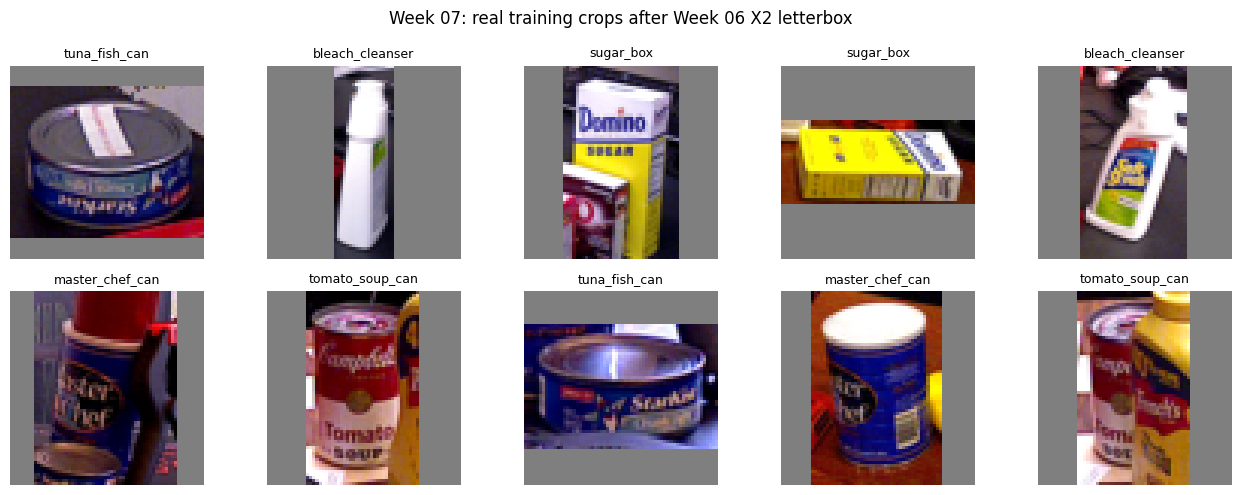

In [5]:
EVAL_TRANSFORM=transforms.Compose([transforms.ToTensor(),transforms.Normalize([.5]*3,[.5]*3)])

def object_crop(row,padding=.08):
    with Image.open(row['rgb_path']) as raw:
        im=raw.convert('RGB'); W,H=im.size
        x,y,w,h=(int(row[k]) for k in ['x','y','w','h'])
        px,py=int(w*padding),int(h*padding)
        return im.crop((max(0,x-px),max(0,y-py),min(W,x+w+px),min(H,y+h+py)))

def resize_letterbox(im,size=IMAGE_SIZE):
    small=ImageOps.contain(im,(size,size),method=Image.Resampling.BILINEAR)
    canvas=Image.new('RGB',(size,size),(127,127,127))
    canvas.paste(small,((size-small.width)//2,(size-small.height)//2))
    return canvas

class CropDataset(Dataset):
    def __init__(self,frame): self.frame=frame.reset_index(drop=True)
    def __len__(self): return len(self.frame)
    def __getitem__(self,idx):
        row=self.frame.iloc[idx]
        im=resize_letterbox(object_crop(row,padding=.08))
        return EVAL_TRANSFORM(im), CLASS_TO_INDEX[int(row.obj_id)]

fig, axes=plt.subplots(2,5,figsize=(13,5))
for ax,(_,r) in zip(axes.ravel(),train_df.groupby('obj_id',sort=False).head(2).iterrows()):
    ax.imshow(resize_letterbox(object_crop(r)))
    ax.set_title(str(r['class_name']),fontsize=9); ax.axis('off')
for ax in axes.ravel(): ax.axis('off')
plt.suptitle('Week 07: real training crops after Week 06 X2 letterbox')
plt.tight_layout(); plt.savefig(OUTPUT_DIR/'training_crop_examples.png',dpi=160,bbox_inches='tight'); plt.show()

## E. CNN architecture and sanity check
**Conv2D** learns local visual patterns by sliding spatial filters over RGB images. **ReLU** adds nonlinearity. **MaxPool2D** reduces spatial size. **AdaptiveAvgPool2D** ensures a compact fixed-size representation. A dense classification head produces five **logits** for `CrossEntropyLoss` (no softmax is used during training).

Reusing the Week 06 `CompactCNN` shape is intentional: Week 07 tests that architecture with the now-supported letterbox preprocessing, rather than tuning a new network family without evidence.

In [6]:
class CompactCNN(nn.Module):
    def __init__(self,dropout=DROPOUT,num_classes=5):
        super().__init__()
        self.features=nn.Sequential(
            nn.Conv2d(3,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(64,96,3,padding=1),nn.ReLU(),nn.AdaptiveAvgPool2d((4,4)),
        )
        self.head=nn.Sequential(nn.Flatten(),nn.Linear(96*4*4,128),nn.ReLU(),
                                nn.Dropout(dropout),nn.Linear(128,num_classes))
    def forward(self,x): return self.head(self.features(x))

seed_everything()
model=CompactCNN().to(DEVICE)
with torch.no_grad():
    trial=torch.zeros(2,3,IMAGE_SIZE,IMAGE_SIZE,device=DEVICE)
    trial_logits=model.eval()(trial)
assert tuple(trial_logits.shape)==(2,5)
print('Input:',tuple(trial.shape),'Output logits:',tuple(trial_logits.shape))
print('Trainable parameters:',sum(p.numel() for p in model.parameters() if p.requires_grad))
print(model)

Input: (2, 3, 64, 64) Output logits: (2, 5)
Trainable parameters: 272165
CompactCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1536, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=5, bias=True)
  )
)


## F. Train one predeclared CNN, selecting the checkpoint only on validation loss
This cell writes the training history, checkpoint and learning curves. It does not access `test_df` or test images. The same optimizer and stop rule as Week 06 are preserved.

Epoch 01/15 | train 1.1681/0.554 | val 0.4201/0.923
Epoch 02/15 | train 0.1647/0.948 | val 0.6026/0.768
Epoch 03/15 | train 0.0241/0.993 | val 0.5319/0.869
Epoch 04/15 | train 0.0132/0.994 | val 0.3431/0.867
Epoch 05/15 | train 0.0147/0.994 | val 0.5244/0.867
Epoch 06/15 | train 0.0048/0.999 | val 0.4790/0.867
Epoch 07/15 | train 0.0015/1.000 | val 1.1366/0.800
Epoch 08/15 | train 0.0008/1.000 | val 0.6388/0.851
Early stopping triggered.
Best checkpoint epoch: 4 | Best validation loss: 0.343059
Training seconds: 102.2


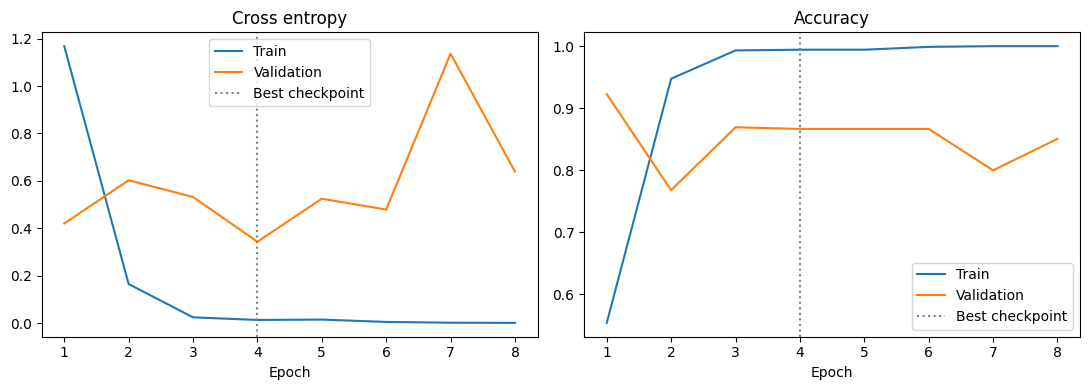

In [7]:
train_loader=DataLoader(CropDataset(train_df),batch_size=BATCH_SIZE,shuffle=True,num_workers=0,
                        generator=torch.Generator().manual_seed(SEED))
val_loader=DataLoader(CropDataset(val_df),batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
seed_everything()
model=CompactCNN().to(DEVICE)
optimizer=torch.optim.Adam(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)

def run_epoch(model,loader,optimizer=None):
    training=optimizer is not None
    model.train(training)
    total_loss=correct=n=0
    for xb,yb in loader:
        xb,yb=xb.to(DEVICE),yb.to(DEVICE)
        if training: optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            logits=model(xb); loss=loss_fn(logits,yb)
            if training: loss.backward(); optimizer.step()
        total_loss+=float(loss.item())*len(yb)
        correct+=int((logits.argmax(1)==yb).sum().item()); n+=len(yb)
    assert n>0
    return total_loss/n,correct/n

best_loss=float('inf'); best_epoch=0; best_state=None; stale=0; history=[]
t0=time.time()
for epoch in range(1,MAX_EPOCHS+1):
    tl,ta=run_epoch(model,train_loader,optimizer=optimizer)
    vl,va=run_epoch(model,val_loader)
    history.append(dict(epoch=epoch,train_loss=tl,train_accuracy=ta,val_loss=vl,val_accuracy=va))
    print(f'Epoch {epoch:02d}/{MAX_EPOCHS} | train {tl:.4f}/{ta:.3f} | val {vl:.4f}/{va:.3f}')
    if vl < best_loss-1e-6:
        best_loss=vl; best_epoch=epoch; stale=0; best_state=copy.deepcopy(model.state_dict())
    else:
        stale+=1
        if stale>=EARLY_STOPPING_PATIENCE:
            print('Early stopping triggered.'); break
assert best_state is not None
model.load_state_dict(best_state)
CHECKPOINT_PATH=CHECKPOINT_DIR/'week07_compact_cnn_letterbox.pt'
torch.save(best_state,CHECKPOINT_PATH)
history_df=pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR/'training_history.csv',index=False)
print('Best checkpoint epoch:',best_epoch,'| Best validation loss:',round(best_loss,6))
print('Training seconds:',round(time.time()-t0,1))

fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(history_df.epoch,history_df.train_loss,label='Train')
axes[0].plot(history_df.epoch,history_df.val_loss,label='Validation')
axes[0].axvline(best_epoch,color='gray',ls=':',label='Best checkpoint')
axes[0].set_title('Cross entropy');axes[0].set_xlabel('Epoch');axes[0].legend()
axes[1].plot(history_df.epoch,history_df.train_accuracy,label='Train')
axes[1].plot(history_df.epoch,history_df.val_accuracy,label='Validation')
axes[1].axvline(best_epoch,color='gray',ls=':',label='Best checkpoint')
axes[1].set_title('Accuracy');axes[1].set_xlabel('Epoch');axes[1].legend()
plt.tight_layout();plt.savefig(OUTPUT_DIR/'training_curves.png',dpi=160,bbox_inches='tight');plt.show()

## G. Validation-only diagnostic (no test yet)
Report accuracy and macro-F1, see class-specific weaknesses, and examine a confusion matrix. This is where model debugging belongs. **Do not change the Week 07 architecture after seeing its final test score.**

Best-checkpoint VALIDATION accuracy: 0.8667 macro-F1: 0.8611
                 precision    recall  f1-score   support

tomato_soup_can       0.68      1.00      0.81        75
      sugar_box       0.83      0.52      0.64        75
master_chef_can       1.00      0.83      0.91        75
  tuna_fish_can       0.93      0.99      0.95        75
bleach_cleanser       1.00      1.00      1.00        75

       accuracy                           0.87       375
      macro avg       0.89      0.87      0.86       375
   weighted avg       0.89      0.87      0.86       375



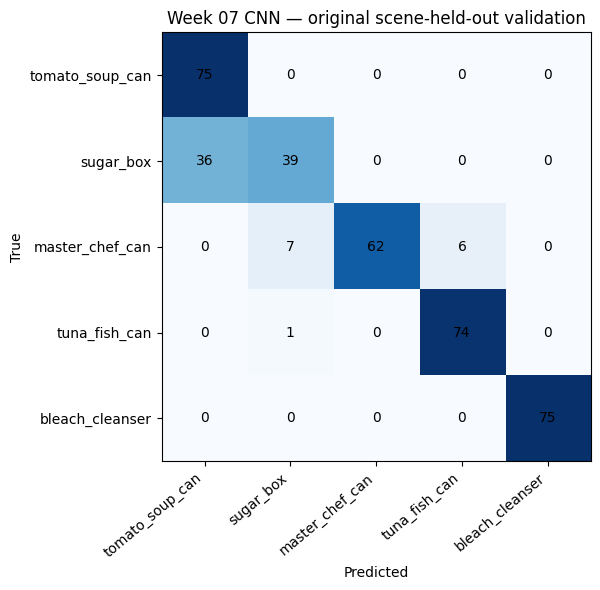

In [8]:
@torch.no_grad()
def predict_dataframe(model,frame):
    model.eval(); loader=DataLoader(CropDataset(frame),batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
    out=[]; pos=0
    for xb,yb in loader:
        logits=model(xb.to(DEVICE))
        probs=torch.softmax(logits,dim=1).cpu().numpy()
        pred=probs.argmax(axis=1)
        for j in range(len(yb)):
            row=frame.iloc[pos+j]
            out.append(dict(split='validation',scene_id=int(row.scene_id),im_id=int(row.im_id),
                            instance_idx=int(row.instance_idx),obj_id=int(row.obj_id),
                            true_index=int(yb[j]),pred_index=int(pred[j]),
                            true_class=CLASSES[int(yb[j])],pred_class=CLASSES[int(pred[j])],
                            confidence=float(probs[j].max()),correct=bool(pred[j]==int(yb[j])),
                            rgb_path=str(row.rgb_path),x=int(row.x),y=int(row.y),w=int(row.w),h=int(row.h)))
        pos+=len(yb)
    assert pos==len(frame)
    return pd.DataFrame(out)

val_preds=predict_dataframe(model,val_df)
val_acc=accuracy_score(val_preds.true_index,val_preds.pred_index)
val_f1=f1_score(val_preds.true_index,val_preds.pred_index,average='macro',labels=range(5),zero_division=0)
print('Best-checkpoint VALIDATION accuracy:',round(val_acc,4),'macro-F1:',round(val_f1,4))
print(classification_report(val_preds.true_index,val_preds.pred_index,labels=range(5),
                            target_names=CLASSES,zero_division=0))
val_preds.to_csv(OUTPUT_DIR/'validation_predictions.csv',index=False)
val_cm=confusion_matrix(val_preds.true_index,val_preds.pred_index,labels=range(5))
pd.DataFrame(val_cm,index=CLASSES,columns=CLASSES).to_csv(OUTPUT_DIR/'validation_confusion_matrix.csv')
fig,ax=plt.subplots(figsize=(7.4,6))
ax.imshow(val_cm,cmap='Blues');ax.set_xticks(range(5),CLASSES,rotation=40,ha='right')
ax.set_yticks(range(5),CLASSES);ax.set_xlabel('Predicted');ax.set_ylabel('True')
for i in range(5):
    for j in range(5): ax.text(j,i,str(val_cm[i,j]),ha='center',va='center')
plt.title('Week 07 CNN — original scene-held-out validation')
plt.tight_layout();plt.savefig(OUTPUT_DIR/'validation_confusion_matrix.png',dpi=160,bbox_inches='tight');plt.show()

## H. Final held-out test — one-time gate
The model architecture, crop recipe, training parameters and selected checkpoint must already be frozen. This cell **never chooses parameters using test data**. Its result file is used as a guard against inadvertent repeated evaluations. If you are only exploring the notebook, set `RUN_FINAL_TEST=False`.

In [9]:
RUN_FINAL_TEST = True  # Switch to False if you are not ready for final evaluation.
FINAL_RESULT_PATH = OUTPUT_DIR/'week07_final_result.json'

if RUN_FINAL_TEST:
    if FINAL_RESULT_PATH.exists():
        raise RuntimeError('A final test result already exists. Do not rerun/tune on test. See outputs/week07/week07_final_result.json.')
    # Re-load the checkpoint selected solely by validation loss.
    final_model=CompactCNN().to(DEVICE)
    final_model.load_state_dict(torch.load(CHECKPOINT_PATH,map_location=DEVICE,weights_only=True))
    test_preds=predict_dataframe(final_model,test_df)
    test_preds['split']='test'
    y=test_preds.true_index.to_numpy();p=test_preds.pred_index.to_numpy()
    test_acc=float(accuracy_score(y,p))
    test_macro_f1=float(f1_score(y,p,average='macro',labels=range(5),zero_division=0))
    test_weighted_f1=float(f1_score(y,p,average='weighted',labels=range(5),zero_division=0))
    test_cm=confusion_matrix(y,p,labels=range(5))
    precision,recall,f1,support=precision_recall_fscore_support(y,p,labels=range(5),zero_division=0)
    classwise=pd.DataFrame(dict(class_name=CLASSES,support=support,precision=precision,recall=recall,f1=f1))
    classwise.to_csv(OUTPUT_DIR/'test_classwise.csv',index=False)
    pd.DataFrame(test_cm,index=CLASSES,columns=CLASSES).to_csv(OUTPUT_DIR/'test_confusion_matrix.csv')
    test_preds.to_csv(OUTPUT_DIR/'final_test_predictions.csv',index=False)
    final_result=dict(experiment='week07_compact_cnn_letterbox',run_utc=datetime.now(timezone.utc).isoformat(),
                      dataset='YCB-V BOP19 internal scene-held-out split',
                      n_train=len(train_df),n_validation=len(val_df),n_test=len(test_df),
                      class_ids=SELECTED_OBJ_IDS,class_names=CLASSES,
                      best_epoch=int(best_epoch),best_validation_loss=float(best_loss),
                      validation_accuracy=float(val_acc),validation_macro_f1=float(val_f1),
                      test_accuracy=test_acc,test_macro_f1=test_macro_f1,test_weighted_f1=test_weighted_f1,
                      correct_test=int((y==p).sum()),errors_test=int((y!=p).sum()),
                      comparison_week06_x2_accuracy=283/450,comparison_week06_x2_macro_f1=0.6468,
                      delta_accuracy_vs_week06_x2=test_acc-283/450,delta_macro_f1_vs_week06_x2=test_macro_f1-.6468,
                      training=dict(epochs_limit=MAX_EPOCHS,patience=EARLY_STOPPING_PATIENCE,
                                    lr=LR,batch_size=BATCH_SIZE,weight_decay=WEIGHT_DECAY,dropout=DROPOUT,
                                    preprocessing='8% bbox padding + 64x64 letterbox'))
    FINAL_RESULT_PATH.write_text(json.dumps(final_result,indent=2),encoding='utf-8')
    print('ONE-TIME TEST — CNN accuracy:',f'{test_acc:.2%}','macro-F1:',f'{test_macro_f1:.4f}')
    print('Week 06 X2 MLP accuracy:',f'{283/450:.2%}','macro-F1: 0.6468')
    print('Delta accuracy:',f'{100*(test_acc-283/450):+.2f} percentage points')
    print(classification_report(y,p,labels=range(5),target_names=CLASSES,zero_division=0))
    display(classwise.round(4))
else:
    print('Final held-out test was NOT run.')

ONE-TIME TEST — CNN accuracy: 72.67% macro-F1: 0.7132
Week 06 X2 MLP accuracy: 62.89% macro-F1: 0.6468
Delta accuracy: +9.78 percentage points
                 precision    recall  f1-score   support

tomato_soup_can       0.57      0.77      0.65       150
      sugar_box       0.82      1.00      0.90        75
master_chef_can       1.00      0.24      0.39        75
  tuna_fish_can       0.81      1.00      0.89        75
bleach_cleanser       1.00      0.57      0.73        75

       accuracy                           0.73       450
      macro avg       0.84      0.72      0.71       450
   weighted avg       0.79      0.73      0.70       450



,class_name,support,precision,recall,f1
0,tomato_soup_can,150,0.5659,0.7733,0.6535
1,sugar_box,75,0.8242,1.0000,0.9036
2,master_chef_can,75,1.0000,0.2400,0.3871
3,tuna_fish_can,75,0.8065,1.0000,0.8929
4,bleach_cleanser,75,1.0000,0.5733,0.7288


## I. Test plots, representative failures, and honest comparison
Run only after the one-time final test above. Look especially for remaining `tomato_soup_can → bleach_cleanser` and `sugar_box → bleach_cleanser` transitions found in Week 06. The baseline scores below are taken from the prior **executed** notebooks; the Week 07 values are loaded from the current run.

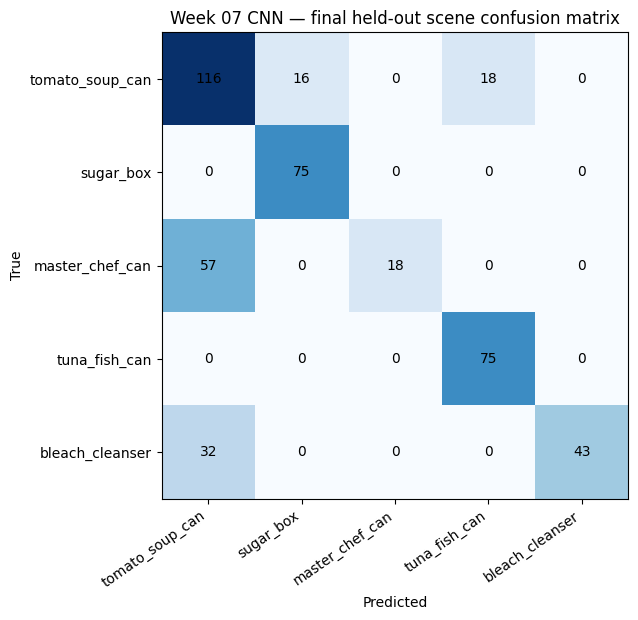

,model,test_accuracy,macro_f1,context
0,Week 03 MLP,0.513300,NaN,64px direct resize
1,Week 04 E1 MLP,0.417778,0.422400,64px direct resize
2,Week 06 X2 MLP,0.628889,0.646800,64px letterbox
3,Week 07 CompactCNN,0.726667,0.713181,64px letterbox


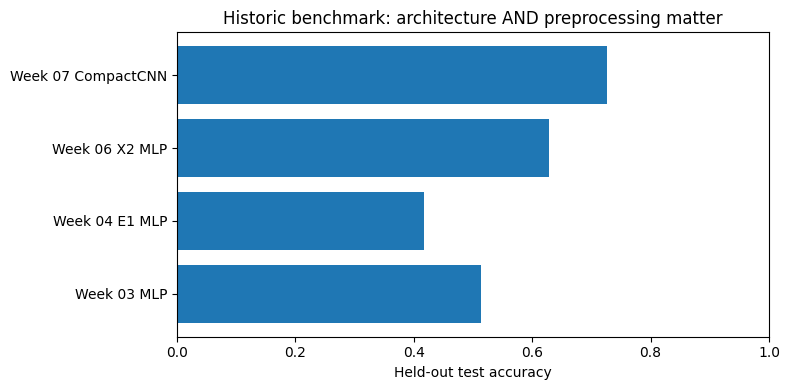

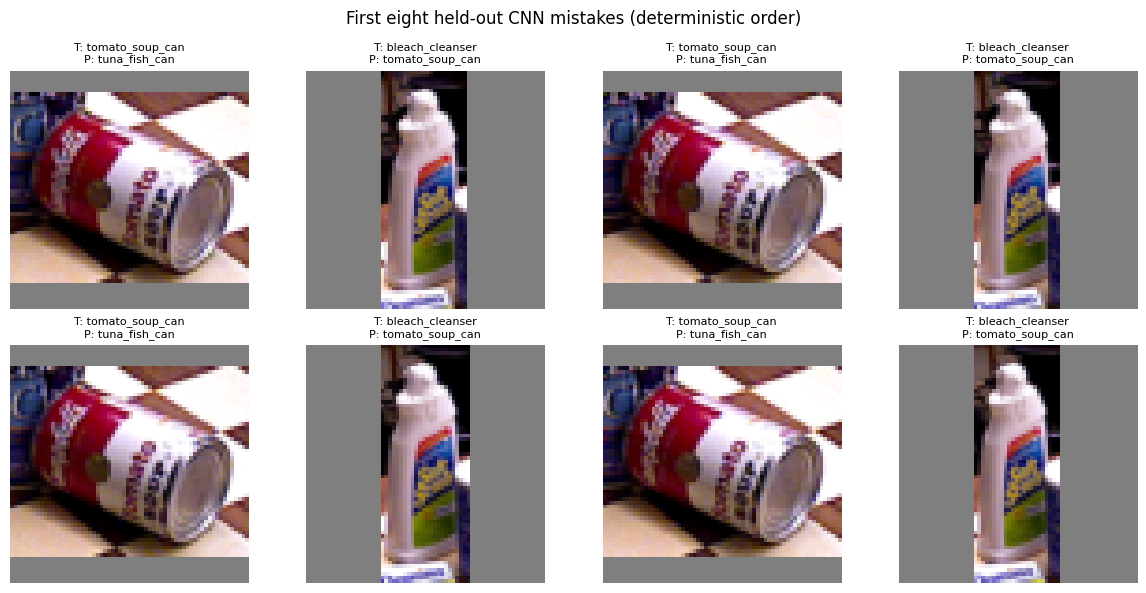

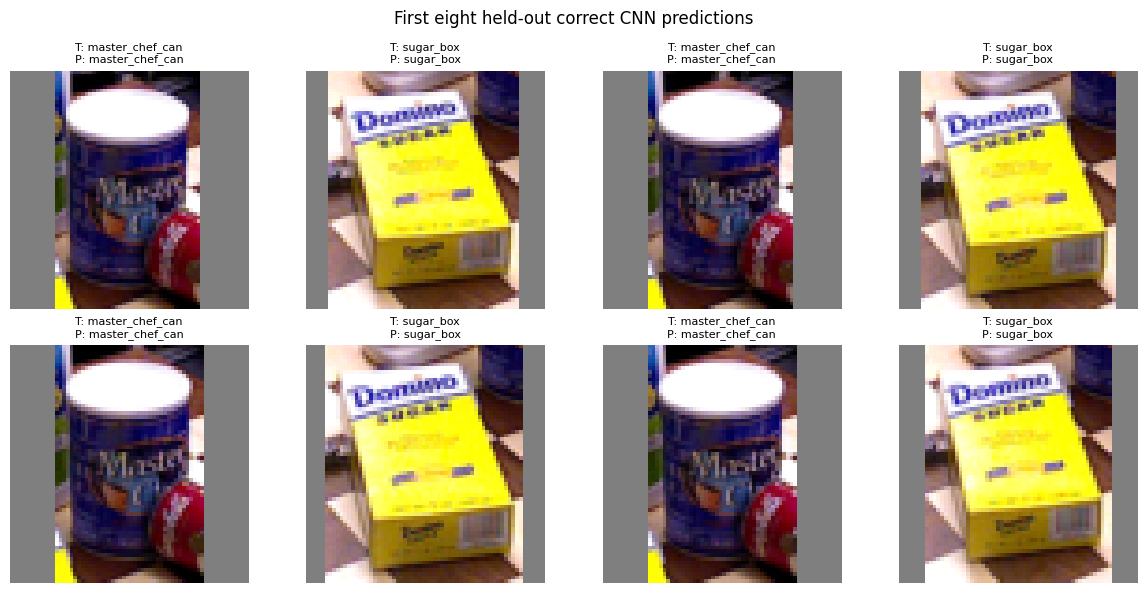

,true_class,pred_class,errors
1,master_chef_can,tomato_soup_can,57
0,bleach_cleanser,tomato_soup_can,32
3,tomato_soup_can,tuna_fish_can,18
2,tomato_soup_can,sugar_box,16


In [10]:
if not FINAL_RESULT_PATH.exists():
    print('No final test recorded. Skip test visualization until Part H has run.')
else:
    # Read saved files; this cell never runs test inference again.
    final_result=json.loads(FINAL_RESULT_PATH.read_text(encoding='utf-8'))
    test_preds=pd.read_csv(OUTPUT_DIR/'final_test_predictions.csv')
    classwise=pd.read_csv(OUTPUT_DIR/'test_classwise.csv')
    cm=pd.read_csv(OUTPUT_DIR/'test_confusion_matrix.csv',index_col=0).to_numpy()
    fig,ax=plt.subplots(figsize=(8,6.3))
    ax.imshow(cm,cmap='Blues'); ax.set_xticks(range(5),CLASSES,rotation=35,ha='right')
    ax.set_yticks(range(5),CLASSES);ax.set_xlabel('Predicted');ax.set_ylabel('True')
    for i in range(5):
        for j in range(5): ax.text(j,i,str(cm[i,j]),ha='center',va='center')
    ax.set_title('Week 07 CNN — final held-out scene confusion matrix')
    plt.tight_layout();plt.savefig(OUTPUT_DIR/'test_confusion_matrix.png',dpi=170,bbox_inches='tight');plt.show()

    compared=pd.DataFrame([
        dict(model='Week 03 MLP',test_accuracy=0.5133,macro_f1=np.nan,context='64px direct resize'),
        dict(model='Week 04 E1 MLP',test_accuracy=188/450,macro_f1=0.4224,context='64px direct resize'),
        dict(model='Week 06 X2 MLP',test_accuracy=283/450,macro_f1=.6468,context='64px letterbox'),
        dict(model='Week 07 CompactCNN',test_accuracy=final_result['test_accuracy'],
             macro_f1=final_result['test_macro_f1'],context='64px letterbox'),
    ])
    compared.to_csv(OUTPUT_DIR/'model_comparison.csv',index=False)
    display(compared)
    fig,ax=plt.subplots(figsize=(8,4))
    ax.barh(compared['model'],compared['test_accuracy'])
    ax.set_xlim(0,1);ax.set_xlabel('Held-out test accuracy')
    ax.set_title('Historic benchmark: architecture AND preprocessing matter')
    plt.tight_layout();plt.savefig(OUTPUT_DIR/'historic_accuracy_comparison.png',dpi=160,bbox_inches='tight');plt.show()

    # Export an *inspectable* example gallery selected by stable test ordering, not by model performance.
    def draw_gallery(sample,filename,title):
        if len(sample)==0: return
        fig,axs=plt.subplots(2,4,figsize=(12,6)); axs=axs.ravel()
        for ax,(_,row) in zip(axs,sample.head(8).iterrows()):
            ax.imshow(resize_letterbox(object_crop(row)))
            ax.set_title(f'T: {row.true_class}\nP: {row.pred_class}',fontsize=8);ax.axis('off')
        for ax in axs: ax.axis('off')
        fig.suptitle(title);plt.tight_layout();plt.savefig(OUTPUT_DIR/filename,dpi=160,bbox_inches='tight');plt.show()
    wrong=test_preds[~test_preds.correct.astype(bool)].sort_values(['scene_id','im_id','instance_idx'])
    correct=test_preds[test_preds.correct.astype(bool)].sort_values(['scene_id','im_id','instance_idx'])
    draw_gallery(wrong,'representative_errors.png','First eight held-out CNN mistakes (deterministic order)')
    draw_gallery(correct,'representative_correct.png','First eight held-out correct CNN predictions')

    transitions=(test_preds[~test_preds.correct.astype(bool)]
                 .groupby(['true_class','pred_class']).size().rename('errors').reset_index()
                 .sort_values('errors',ascending=False))
    transitions.to_csv(OUTPUT_DIR/'error_transitions.csv',index=False)
    display(transitions.head(10))